In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
import math
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goaldistr):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goaldistr=goaldistr
        self.memory=np.array([])
        random.seed(100)
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    #good if a = memory but not oposite
    def KL(self,a,b):
       
        if len(a)<len(b):
            return 1
        return np.sum(a*np.log(a/b))

    #very bad
    def JS(self,a,b):
        if len(a)<len(b):
            return 1
        M= 0.5 * (a[-100:]+b)
        return 0.5* self.KL(a[-100:],M)+ 0.5 * self.KL(b,M)
    #not good
    def hellinger(self,a,b):
        if len(a)<len(b):
            return 1
        a=a[-100:]
        a/=np.sum(a)
        b/=np.sum(b)
        return np.sqrt(0.5* np.sum((np.sqrt(a)-np.sqrt(b))**2))
        
    
    def episodeRewards(self,episodes):
        result=len(episodes)
        self.memory=np.append(self.memory,result)
        reward =-self.KL(self.memory[-1000:],self.goaldistr)
        
        for i in range(len(episodes)-1,-1,-1):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
                continue
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

### learner rewards

In [4]:
"""
values=[]
goal=130
for i in range(goal*3):
    values.append(goal-abs(goal-i))
plt.plot(values)
plt.axvline(x= goal,color ='g')
plt.axhline(y= 0,color ='r',linestyle = "dashed")"""

'\nvalues=[]\ngoal=130\nfor i in range(goal*3):\n    values.append(goal-abs(goal-i))\nplt.plot(values)\nplt.axvline(x= goal,color =\'g\')\nplt.axhline(y= 0,color =\'r\',linestyle = "dashed")'

130.61278650268224
19.37302270253779


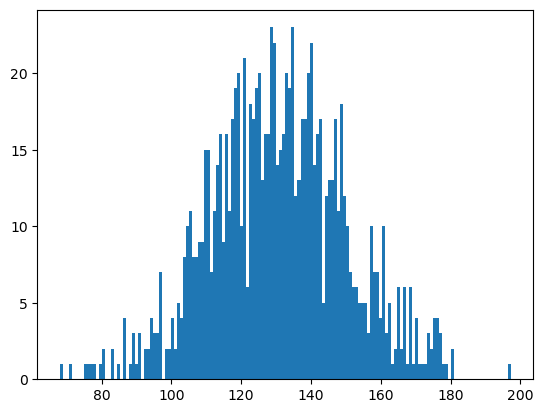

In [5]:
goaldistr=np.random.normal(loc=130,scale=20,size=1000)
print(np.mean(goaldistr))
print(np.std(goaldistr))
plt.hist(goaldistr,150)
plt.savefig("SVG/KLrewarddistr.svg")

### Test

In [6]:
episodeNumber=30000
timeSteps=10000
episodesResults=[]
episodesTestResults=[]
episodesTestResultsDeviation=[]
numberOfTest=50
qagent= Qlearning(0.1,0.99,0.1,2,goaldistr)
pos_space=np.linspace(-2.4,2.4,10)
vel_space=np.linspace(4,4,10)
ang_space=np.linspace(-0.2095,0.2095,10)
ang_vel_space=np.linspace(-4,4,10)

In [7]:
goal=130

In [8]:
for episodeIndex in range(episodeNumber):
    
    state,_=env.reset()
    state=treatState(state)
    #print("episode: ",episodeIndex)
    episodeObservation=[]
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        episodeObservation.append([tuple(state),action,tuple(next_state)])
        #qagent.update(tuple(state),action,tuple(next_state),reward)
        state=next_state
        if (terminated):
            #print("Number of steps :",timeIndex)
            #if(episodeIndex %500 ==0):
                #episodesTestResults.append(timeIndex)
            episodesResults.append(timeIndex)
            break

    qagent.episodeRewards(episodeObservation)

    if episodeIndex %250 ==0:
        print(episodeIndex)
    if(episodeIndex %500 ==0):
        qagent.epsilon=0
        testResultList=[]
        for episodeIndex in range(numberOfTest):
    
            state,_=env.reset()
            state=treatState(state)
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=treatState(next_state)
                state=next_state
                if (terminated):
                    testResultList.append(timeIndex)
                    break

        episodesTestResults.append(sum(testResultList)/numberOfTest)
        episodesTestResultsDeviation.append(np.std(episodesTestResults))
        qagent.epsilon=0.1
    


env.close() 

0
250
500
750
1000
1250
1500
1750
2000
2250
2500
2750
3000
3250
3500
3750
4000
4250
4500
4750
5000
5250
5500
5750
6000
6250
6500
6750
7000
7250
7500
7750
8000
8250
8500
8750
9000
9250
9500
9750
10000
10250
10500
10750
11000
11250
11500
11750
12000
12250
12500
12750
13000
13250
13500
13750
14000
14250
14500
14750
15000
15250
15500
15750
16000
16250
16500
16750
17000
17250
17500
17750
18000
18250
18500
18750
19000
19250
19500
19750
20000
20250
20500
20750
21000
21250
21500
21750
22000
22250
22500
22750
23000
23250
23500
23750
24000
24250
24500
24750
25000
25250
25500
25750
26000
26250
26500
26750
27000
27250
27500
27750
28000
28250
28500
28750
29000
29250
29500
29750


96.7986


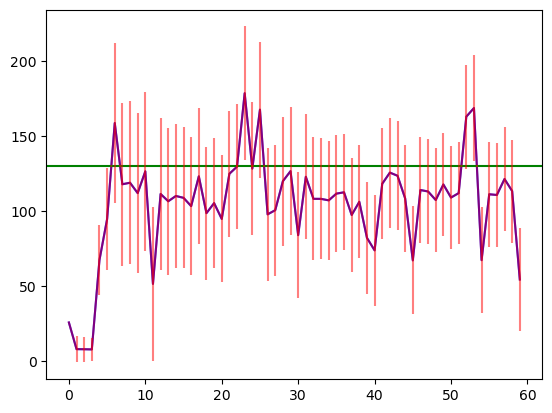

In [9]:
plt.plot(episodesTestResults,color ='b')
plt.axhline(y= goal,color ='g')
plt.errorbar(range(len(episodesTestResults)),episodesTestResults,yerr=episodesTestResultsDeviation,color ='r',alpha=0.5)
plt.savefig("SVG/KLreward1.svg")
print(sum(episodesResults)/len(episodesResults))

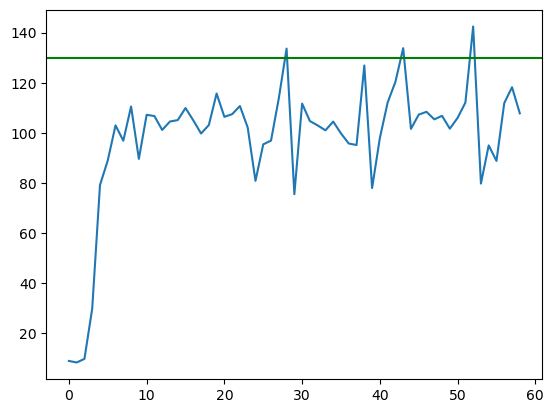

In [10]:
previous100AveragePlot=[]
for i in range(1,len(episodesTestResults)):
    previous100AveragePlot.append(sum(episodesResults[(i*500)-100:(i*500)])/100)

plt.plot(previous100AveragePlot)
plt.axhline(y= goal,color ='g')
plt.savefig("SVG/KLreward2.svg")

2718


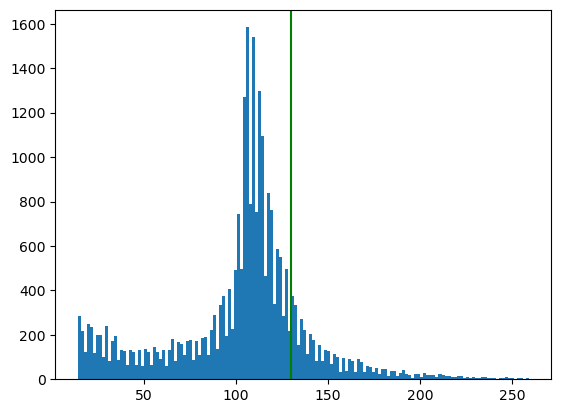

In [11]:
#histogram
episodesResultswithoutOutliers=[]
for i in episodesResults:
    if i >goal * 0.1 and i < goal*2:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/KLreward3.svg")
print(len(episodesResults)-len(episodesResultswithoutOutliers))

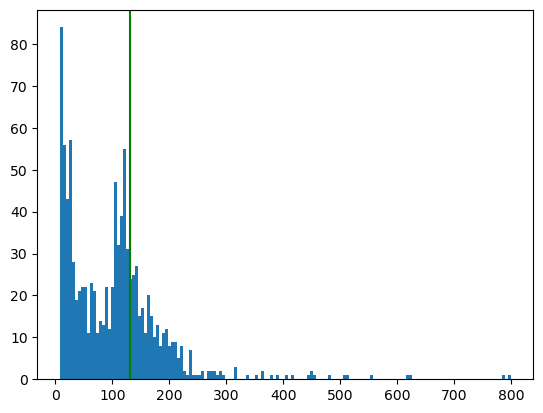

In [12]:
plt.hist(episodesResults[-1000:],bins=150)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/KLreward4.svg")

95.419
86.33555142002628


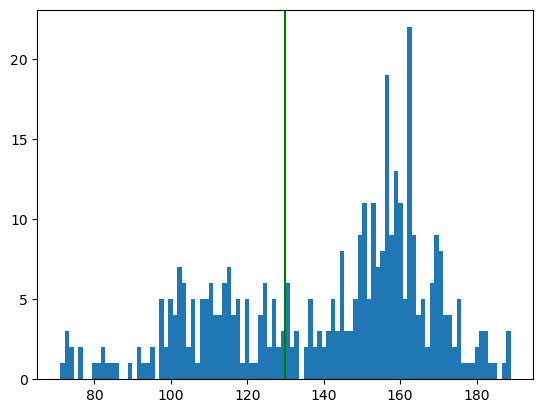

In [13]:
qagent.epsilon=0
last1000testList=[]
for episodeIndex in range(1000):
    
    state,_=env.reset()
    state=treatState(state)
    for timeIndex in range(timeSteps):
        action=qagent.getAction(tuple(state))
        next_state, reward, terminated, truncated, info =env.step(action)
        next_state=treatState(next_state)
        state=next_state
        if (terminated):
            last1000testList.append(timeIndex)
            break



episodesResultswithoutOutliers=[]
for i in last1000testList:
    if i >goal -60 and i < goal+60:
        episodesResultswithoutOutliers.append(i)
plt.hist(episodesResultswithoutOutliers,bins=100)
plt.axvline(x= goal,color ='g')
plt.savefig("SVG/KLreward5.svg")
print(np.mean(last1000testList))
print(np.std(last1000testList))

In [14]:
print(np.mean(episodesResults[-1000:]))
print(np.std(episodesResults[-1000:]))

102.526
86.45969768626306


In [15]:
goal7LearnerEp=episodesResults
%store goal7LearnerEp
goal7learnerTestEp=episodesTestResults
%store goal7learnerTestEp

Stored 'goal7LearnerEp' (list)
Stored 'goal7learnerTestEp' (list)
